# Activity 2 – Binary Classification with Logistic Regression: Predicting Telecom Customer Churn

**Course:** Regression and Classification Algorithms (T.Y. B.Tech AI & DS, Semester V, 2026–27) · **Assessment:** CIE 2, Activity 2 (5 marks)
**Student:** [Your Name] · **Roll No.:** [Your Roll No.] · **GitHub:** [https://github.com/complexiota](https://github.com/complexiota)

**Dataset:** Telco Customer Churn (IBM sample dataset), 7,043 customers · **Task:** predict whether a customer will **churn** (cancel the service) so that a retention team can act *before* the customer leaves.

> **How to read this notebook.** It follows the "Data Scientist's Thinking Cycle": frame the problem and the cost of each error → understand the data → explore → baseline → build without leakage → evaluate with the right metrics → choose a decision threshold with a reason → state limits. Every number has a sentence of interpretation, and a decision log is at the end.

In [1]:
import os, platform, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             classification_report)

SEED = 42                     # one seed everywhere -> reproducible
np.random.seed(SEED)
for d in ("images", "results", "models"):
    os.makedirs(d, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.4f}".format

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", bbox_inches="tight")
    plt.show()

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python 3.12.3 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 1. Frame the problem  *(thinking-cycle stage 1)*

**Who is the user?** The customer-retention team of a telecom company (phone + internet).

**What decision does the model support?** Each month the team can contact a limited number of customers with a retention offer (a discount, a plan review, a call). The model outputs the **probability that a customer will churn**; the team turns that into a yes/no list of "customers to contact".

**The two classes (stated clearly):**
* **Class 1 – positive – "Churned":** the customer left the company in the last month.
* **Class 0 – negative – "Stayed":** the customer is still with the company.

**What happens when the model is wrong?**
* **False negative (FN)** – a customer who *will* leave is not flagged → we get no chance to save them → **lost revenue** (the expensive mistake).
* **False positive (FP)** – a customer who would have stayed is flagged → we spend an unnecessary retention offer on them (a smaller, but real cost: money, and the risk of teaching loyal customers to wait for discounts).

So the team cares more about **finding churners (recall)** than about being right every time a flag is raised – but not at any price, because flagging everybody is also costly. We therefore judge the model with **recall, precision, F1, PR-AUC and ROC-AUC**, and with an explicit **cost calculation** – not with accuracy alone.

**Target (y):** `Churn` (Yes → 1, No → 0). **Inputs (X):** tenure, monthly charge and the services/contract/billing choices of the customer (Section 3).
**Success looks like:** clearly better than the "predict nobody churns" baseline, with a threshold chosen for the business cost, and a model whose probabilities can be explained to a manager.

## 2. Understand the data  *(stage 2)*

### 2.1 Source and data dictionary
* **Source:** *Telco Customer Churn* sample dataset published by **IBM** (IBM Cognos Analytics sample data). Copy used: <https://github.com/IBM/telco-customer-churn-on-icp4d> (file `data/Telco-Customer-Churn.csv`).
* **File type / size:** CSV, **7,043 rows × 21 columns**.
* **One row = one customer account** of a (fictional-company) telecom provider. Customer IDs are anonymous codes; there are no names, addresses, phone numbers or e-mails, so no personal data is used. Because it is a published **sample** dataset, results illustrate the *method*; they are not claims about any real company.

| Column(s) | Meaning | Type | Role |
|---|---|---|---|
| `customerID` | Anonymous account code | ID | **excluded** (identifier, never a feature) |
| `gender`, `SeniorCitizen` | Demographics | category / 0-1 | **excluded** – ethics (see decision log) |
| `Partner`, `Dependents` | Lives with partner / has dependents | Yes/No | feature |
| `tenure` | Months the customer has been with the company | number (0–72) | feature |
| `PhoneService`, `MultipleLines` | Phone service and extra lines | Yes/No | feature |
| `InternetService` | DSL / Fiber optic / No | category | feature |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Add-on services | Yes/No | features |
| `Contract` | Month-to-month / One year / Two year | category | feature |
| `PaperlessBilling`, `PaymentMethod` | Billing choices | Yes/No / category | features |
| `MonthlyCharges` | Current monthly bill | USD | feature |
| `TotalCharges` | Total billed so far | USD | **excluded** – (≈ tenure × monthly, redundant) |
| `Churn` | Left in the last month? | Yes/No | **target (y)** |

In [2]:
raw = pd.read_csv("data/Telco-Customer-Churn.csv")
print("Shape (rows, columns):", raw.shape)
display(raw.head(5).T)
print("\nData types:")
print(raw.dtypes.value_counts().to_string())

Shape (rows, columns): (7043, 21)


,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No



Data types:
str        18
int64       2
float64     1


### 2.2 Quality checks – types, missing values, duplicates, inconsistent labels

In [3]:
# 1) TotalCharges is stored as text: find out why
tc = pd.to_numeric(raw["TotalCharges"].astype(str).str.strip(), errors="coerce")
bad = raw[tc.isna()]
print(f"Rows where TotalCharges cannot be read as a number: {len(bad)}")
display(bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(11))

# 2) Missing values, duplicates, repeated customer IDs
print("\nMissing values (real NaN):", int(raw.isna().sum().sum()))
print("Duplicate rows:", raw.duplicated().sum(), "| Duplicate customer IDs:", raw["customerID"].duplicated().sum())

# 3) Inconsistent / redundant labels in the categorical columns
cat_cols = raw.select_dtypes(exclude="number").columns.drop(["customerID", "TotalCharges"])
for c in cat_cols:
    print(f"{c:18s}", sorted(raw[c].unique()))

Rows where TotalCharges cannot be read as a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.5500,,No
753,3115-CZMZD,0,20.2500,,No
936,5709-LVOEQ,0,80.8500,,No
1082,4367-NUYAO,0,25.7500,,No
1340,1371-DWPAZ,0,56.0500,,No
3331,7644-OMVMY,0,19.8500,,No
3826,3213-VVOLG,0,25.3500,,No
4380,2520-SGTTA,0,20.0000,,No
5218,2923-ARZLG,0,19.7000,,No
6670,4075-WKNIU,0,73.3500,,No



Missing values (real NaN): 0
Duplicate rows: 0 | Duplicate customer IDs: 0
gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


**Findings and decisions**
* `TotalCharges` is text because **11 rows contain a blank**. All 11 have `tenure = 0` (brand-new customers who have not been billed yet) and none churned, so a blank really means **0 dollars billed so far** → fill with 0 (alternative: delete 11 rows; rejected because they are legitimate customers). `TotalCharges` is not used as a model feature anyway (see 3.1).
* There are **no real missing values, no duplicates and no repeated IDs**.
* Seven add-on columns use **three** labels: `Yes`, `No` and `No internet service` (or `No phone service`). The third label only repeats what `InternetService` / `PhoneService` already say, so it is **merged into `No`** to avoid redundant columns.

In [4]:
df = raw.copy()
df["TotalCharges"] = tc.fillna(0.0)
addon_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for c in addon_cols:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})
df["y"] = (df["Churn"] == "Yes").astype(int)          # 1 = churned (positive class), 0 = stayed
print("Cleaned shape:", df.shape, "| remaining NaN:", int(df.isna().sum().sum()))

Cleaned shape: (7043, 22) | remaining NaN: 0


### 2.3 Class balance

             records  share
Churn                      
0 – Stayed      5174 0.7346
1 – Churned     1869 0.2654


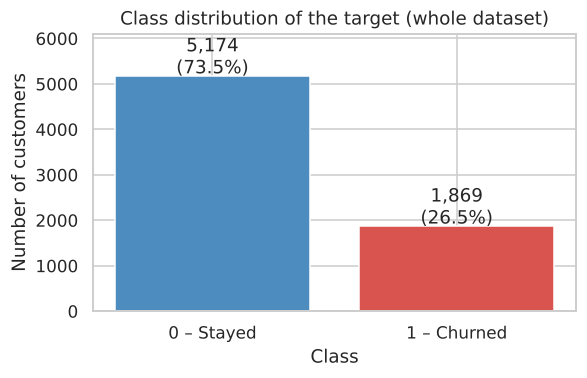

In [5]:
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
shares = counts / counts.sum()
print(pd.DataFrame({"records": counts, "share": shares}).rename(index={"No": "0 – Stayed", "Yes": "1 – Churned"}))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(["0 – Stayed", "1 – Churned"], counts.values, color=["#4c8cbf", "#d9534f"])
for b, v, s in zip(bars, counts.values, shares.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}\n({s:.1%})", ha="center")
ax.set_title("Class distribution of the target (whole dataset)")
ax.set_xlabel("Class"); ax.set_ylabel("Number of customers"); ax.set_ylim(0, counts.max() * 1.18)
savefig("01_class_distribution")

**Observation.** 5,174 customers stayed (73.5%) and 1,869 churned (26.5%) – roughly 2.8 stayers for every churner. This is **moderately imbalanced**, not extreme, but enough to matter: a model that always says "Stayed" is already 73.5% accurate. We therefore (a) use a **stratified** split, (b) compare against that majority baseline, and (c) judge the model with recall, precision, F1 and PR-AUC, not accuracy alone.

## 3. Explore and prepare the features  *(stages 3 and 5)*

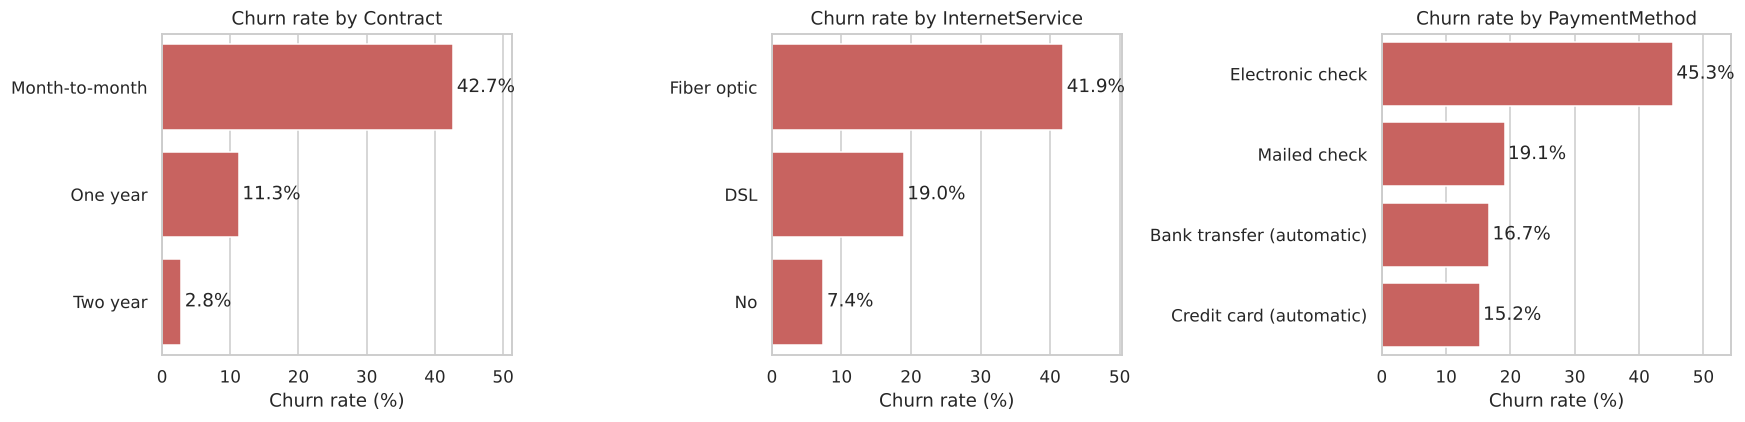

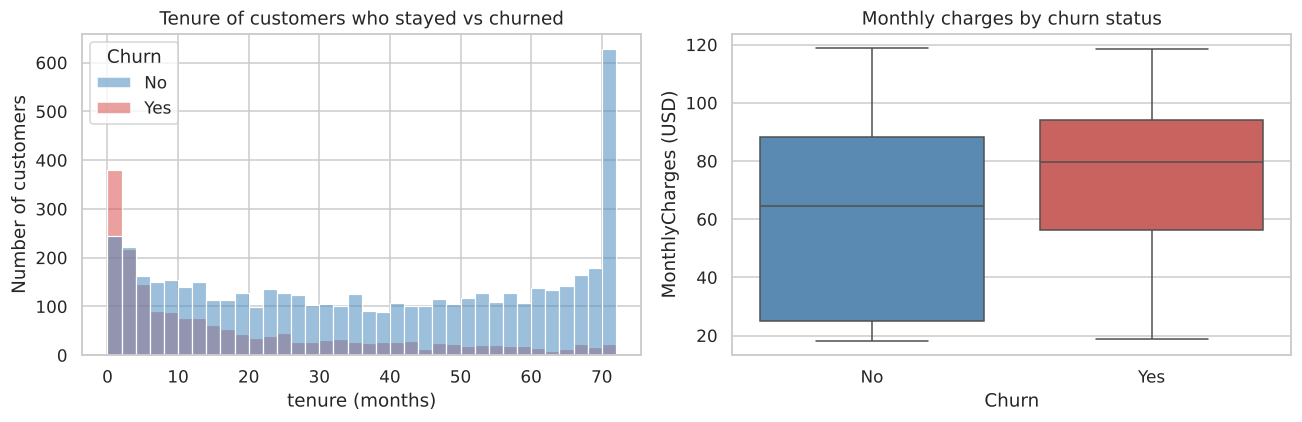

                tenure  MonthlyCharges  TotalCharges
tenure          1.0000          0.2480        0.8260
MonthlyCharges  0.2480          1.0000        0.6510
TotalCharges    0.8260          0.6510        1.0000


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(c)["y"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#d9534f")
    for i, v in enumerate(rate.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
    ax.set_title(f"Churn rate by {c}"); ax.set_xlabel("Churn rate (%)"); ax.set_ylabel("")
    ax.set_xlim(0, rate.max() * 1.2)
savefig("02_churn_rate_by_category")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="layer", alpha=0.55, ax=axes[0], palette={"No": "#4c8cbf", "Yes": "#d9534f"})
axes[0].set_title("Tenure of customers who stayed vs churned"); axes[0].set_xlabel("tenure (months)"); axes[0].set_ylabel("Number of customers")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1], palette={"No": "#4c8cbf", "Yes": "#d9534f"})
axes[1].set_title("Monthly charges by churn status"); axes[1].set_xlabel("Churn"); axes[1].set_ylabel("MonthlyCharges (USD)")
savefig("03_tenure_and_charges")

print(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr().round(3))

**Observation.**
* **Contract:** churn is 42.7% on month-to-month contracts, 11.3% on one-year and only 2.8% on two-year contracts – the strongest pattern in the data.
* **Internet service:** fiber-optic customers churn at 41.9%, DSL at 19.0% and customers with no internet at 7.4%.
* **Payment method:** electronic-check payers churn at 45.3%, against about 15–19% for the other three methods.
* **Tenure:** churners are concentrated in the first months (median tenure about 10 months for churners vs 38 for stayers). Churners also pay more per month (median about $80 vs $64).
* **Feature overlap:** `TotalCharges` is strongly tied to `tenure` (r ≈ 0.83) and to `MonthlyCharges` (r ≈ 0.65), which supports leaving it out.

These are *associations*; for example fiber customers may churn more because of price, competition or service quality – the data cannot tell us which. These patterns suggest that a linear (log-odds) model on contract, tenure and services should work reasonably well.

### 3.1 Which columns become features – and why
* **`customerID` – excluded.** An identifier carries no behaviour; including it would only let the model memorise.
* **`gender`, `SeniorCitizen` – excluded for ethical reasons.** A retention model decides *who gets a discount or a phone call*. Using gender or an age-related flag could lead to different treatment of people for reasons unrelated to their service. The check below shows whether excluding them costs accuracy (cross-validated on the training data only).
* **`TotalCharges` – excluded.** It is almost "tenure × monthly charge" (correlation with tenure ≈ 0.83), so it adds little new information and makes coefficients harder to read. The check below confirms this.
* **Numerical features (scaled):** `tenure`, `MonthlyCharges`.
* **Categorical features (one-hot encoded):** all Yes/No and category columns listed in the data dictionary. **Encoding choice:** one-hot with the first category dropped as the reference (so coefficients are read as "compared with the reference category"), because these categories have no natural order and ordinal numbers would invent a false ordering.
* **Scaling:** `tenure` (0–72) and `MonthlyCharges` (18–119) have different ranges. Logistic regression is fitted by an iterative optimiser, which converges faster and more reliably when features are on similar scales, and scaling also makes coefficients comparable. The scaler is **fitted on training data only**.

In [7]:
NUM = ["tenure", "MonthlyCharges"]
CAT = ["Partner", "Dependents", "PhoneService", "InternetService", "Contract", "PaperlessBilling", "PaymentMethod"] + addon_cols
FEATURES = NUM + CAT
print(f"{len(FEATURES)} features: {len(NUM)} numerical + {len(CAT)} categorical (before one-hot encoding)")

def make_pipeline(num, cat, C=1.0):
    """Preprocessing + model in ONE pipeline: every fit (also inside cross-validation) learns the scaler and
    encoder from its own training part only -> no information leaks from validation/test rows."""
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(C=C, max_iter=1000, random_state=SEED))])

16 features: 2 numerical + 14 categorical (before one-hot encoding)


## 4. Split the data (stratified)  *(stage 5)*

In [8]:
X = df[FEATURES + ["TotalCharges", "SeniorCitizen", "gender"]]       # extra columns kept only for the sensitivity check below
y = df["y"]
X_train_all, X_test_all, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]

summary = pd.DataFrame({
    "rows":        [len(y_train), len(y_test)],
    "0 – Stayed":  [(y_train == 0).sum(), (y_test == 0).sum()],
    "1 – Churned": [(y_train == 1).sum(), (y_test == 1).sum()],
    "churn share": [y_train.mean(), y_test.mean()]}, index=["Training set (80%)", "Test set (20%)"])
display(summary)

,rows,0 – Stayed,1 – Churned,churn share
Training set (80%),5634,4139,1495,0.2654
Test set (20%),1409,1035,374,0.2654


`stratify=y` keeps the churn share the same (≈ 26.5%) in both parts, so the test set is a fair miniature of the whole. **From here on the test set is used only for the final report.** Anything we have to *choose* (the feature set, the threshold) is chosen with 5-fold cross-validation **inside the training set**.

In [9]:
# Sensitivity checks on the feature choices -- using cross-validated ROC-AUC on the TRAINING set only
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
variants = {
    "Chosen set (tenure, MonthlyCharges + categories)":        (NUM, CAT),
    "+ TotalCharges":                                          (NUM + ["TotalCharges"], CAT),
    "+ gender and SeniorCitizen":                              (NUM + ["SeniorCitizen"], CAT + ["gender"]),
}
rows = []
for name, (n_, c_) in variants.items():
    s = cross_val_score(make_pipeline(n_, c_), X_train_all[n_ + c_], y_train, cv=cv5, scoring="roc_auc")
    rows.append({"Feature set": name, "CV ROC-AUC (mean)": s.mean(), "std": s.std()})
display(pd.DataFrame(rows))

,Feature set,CV ROC-AUC (mean),std
0,"Chosen set (tenure, MonthlyCharges + categories)",0.8449,0.0125
1,+ TotalCharges,0.8462,0.0130
2,+ gender and SeniorCitizen,0.8449,0.0122


**Observation.** The cross-validated ROC-AUC is 0.845 for our chosen feature set, 0.846 when `TotalCharges` is added (a difference of 0.001, far smaller than the fold-to-fold spread of about 0.013) and 0.845 when `gender` and `SeniorCitizen` are added (no change). So excluding `gender`, `SeniorCitizen` and `TotalCharges` costs **nothing measurable** – we gain a fairer and simpler model for free.

## 5. Why Linear Regression is unsuitable, and what Logistic Regression does  *(stage 5 – concepts)*

**Why not Linear Regression for a class label?** Linear regression outputs any number on the real line. For a 0/1 target it would predict values like −0.3 or 1.4, which are not probabilities and cannot be interpreted as "chance of churn". A straight line is also pulled around by the 0/1 structure (the errors can never be normally distributed or have constant variance when the target is only 0 or 1), and its predictions have no natural place to cut into two classes.

**Logistic Regression** keeps the linear idea but passes the score through the **sigmoid function** so that the output is always between 0 and 1:

$$z = b_0 + b_1x_1 + \dots + b_px_p,\qquad P(\text{churn}=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}$$

* Large positive z → probability near 1; large negative z → near 0; z = 0 → probability 0.5.
* The result is a **probability**. To get a class label we apply a **decision threshold t**: predict "churn" if probability ≥ t. The usual default is **t = 0.5**, but nothing forces us to use it – the right threshold depends on the cost of each error (Section 9).
* Coefficients are on the **log-odds** scale: +1 in a feature multiplies the *odds* of churn by $e^{b}$ (this multiplier is called the odds ratio). A positive b raises the probability of churn; a negative b lowers it.

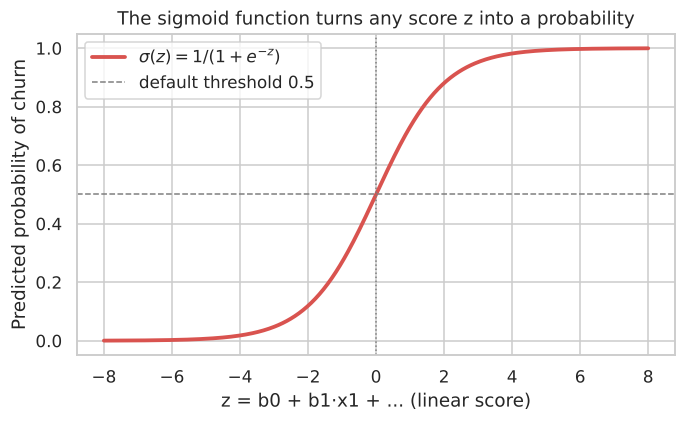

In [10]:
z = np.linspace(-8, 8, 400)
sig = 1 / (1 + np.exp(-z))
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(z, sig, color="#d9534f", lw=2.5, label=r"$\sigma(z)=1/(1+e^{-z})$")
ax.axhline(0.5, color="grey", ls="--", lw=1, label="default threshold 0.5")
ax.axvline(0, color="grey", ls=":", lw=1)
ax.set_title("The sigmoid function turns any score z into a probability")
ax.set_xlabel("z = b0 + b1·x1 + ... (linear score)"); ax.set_ylabel("Predicted probability of churn")
ax.legend()
savefig("04_sigmoid")

**Reading the plot.** The curve is S-shaped: a very low score gives a probability near 0, a very high score gives near 1, and the steepest part – where small changes in the score matter most – is around z = 0 (probability 0.5). The curve never leaves the 0–1 range, which is exactly what a probability needs.

## 6. Baseline and model training  *(stages 4–5)*

**Baseline:** a model that always predicts the **majority class** ("Stayed"). Anything we build must beat it on the metrics that matter.

In [11]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_pred = base.predict(X_test)
print(f"Majority-class baseline predicts '{['Stayed','Churned'][base.classes_[np.argmax(base.class_prior_)]]}' for everybody.")
print(f"  Accuracy = {accuracy_score(y_test, base_pred):.4f}   Precision = {precision_score(y_test, base_pred, zero_division=0):.4f}   "
      f"Recall = {recall_score(y_test, base_pred):.4f}   F1 = {f1_score(y_test, base_pred, zero_division=0):.4f}   ROC-AUC = 0.5000 (no ranking ability)")

Majority-class baseline predicts 'Stayed' for everybody.
  Accuracy = 0.7346   Precision = 0.0000   Recall = 0.0000   F1 = 0.0000   ROC-AUC = 0.5000 (no ranking ability)


**Interpretation.** The baseline already scores ~73% accuracy without finding a single churner (recall = 0). This is exactly why accuracy alone can mislead on imbalanced data: a useless model looks "73% good". We will therefore judge the model on recall, precision, F1, PR-AUC and ROC-AUC.

In [12]:
model = make_pipeline(NUM, CAT, C=1.0).fit(X_train, y_train)      # fitted on training data ONLY
clf = model.named_steps["clf"]
print("Model settings:", {k: v for k, v in clf.get_params().items() if k in ("C", "solver", "max_iter", "class_weight", "random_state")})
print("   regularisation = L2 (the default), C = 1.0 (inverse regularisation strength), class_weight = None (no reweighting)")
print(f"\nIntercept b0 = {clf.intercept_[0]:.4f}")

names = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]
coef = pd.DataFrame({"feature": names, "coefficient (log-odds)": clf.coef_[0]})
coef["odds ratio = e^coef"] = np.exp(coef["coefficient (log-odds)"])
coef["effect on churn"] = np.where(coef["coefficient (log-odds)"] > 0, "raises", "lowers")
coef = coef.sort_values("coefficient (log-odds)", ascending=False).reset_index(drop=True)
display(coef)

sd = dict(zip(NUM, model.named_steps["prep"].named_transformers_["num"].scale_))
print("\nNumeric features are standardised: +1 in the table = +1 standard deviation. 1 SD =",
      {k: round(v, 1) for k, v in sd.items()})

Model settings: {'C': 1.0, 'class_weight': None, 'max_iter': 1000, 'random_state': 42, 'solver': 'lbfgs'}
   regularisation = L2 (the default), C = 1.0 (inverse regularisation strength), class_weight = None (no reweighting)

Intercept b0 = -1.6370


,feature,coefficient (log-odds),odds ratio = e^coef,effect on churn
0,InternetService_Fiber optic,1.0938,2.9857,raises
1,PaymentMethod_Electronic check,0.3898,1.4767,raises
2,PaperlessBilling_Yes,0.3740,1.4535,raises
3,MultipleLines_Yes,0.3636,1.4385,raises
4,StreamingTV_Yes,0.3473,1.4152,raises
5,StreamingMovies_Yes,0.3472,1.4151,raises
6,PaymentMethod_Mailed check,0.1005,1.1058,raises
7,Partner_Yes,0.0351,1.0358,raises
8,DeviceProtection_Yes,0.0328,1.0334,raises
9,PaymentMethod_Credit card (automatic),-0.0391,0.9616,lowers



Numeric features are standardised: +1 in the table = +1 standard deviation. 1 SD = {'tenure': np.float64(24.6), 'MonthlyCharges': np.float64(30.1)}


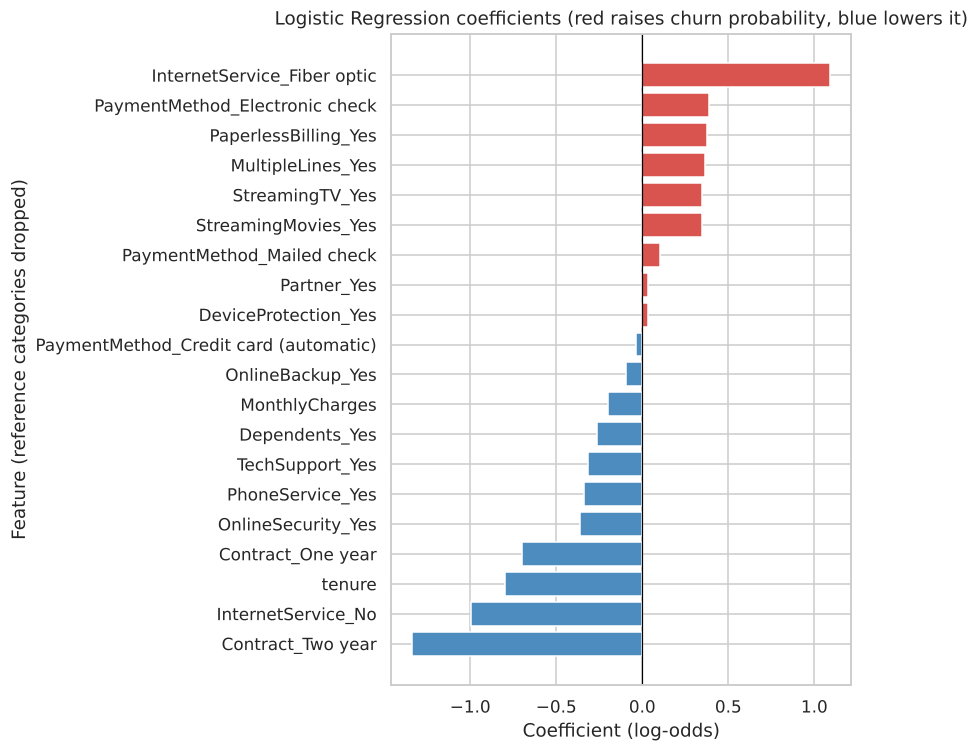

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
c = coef.sort_values("coefficient (log-odds)")
ax.barh(c["feature"], c["coefficient (log-odds)"], color=np.where(c["coefficient (log-odds)"] > 0, "#d9534f", "#4c8cbf"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Logistic Regression coefficients (red raises churn probability, blue lowers it)")
ax.set_xlabel("Coefficient (log-odds)"); ax.set_ylabel("Feature (reference categories dropped)")
savefig("05_coefficients")

**Reading the coefficients** (each effect is "compared with the reference category, other features fixed"; reference categories are the ones dropped by the encoder: *Month-to-month* contract, *DSL* internet, *Bank transfer (automatic)* payment).
* **Raises churn probability:** **Fiber-optic internet** (coefficient +1.09, odds ratio ≈ 3.0 – the odds of churn are about three times those of a DSL customer), electronic-check payment (OR ≈ 1.5), paperless billing (≈ 1.5), multiple phone lines (≈ 1.4), and streaming TV / movies (≈ 1.4 each).
* **Lowers churn probability:** a **two-year contract** (coefficient −1.34, OR ≈ 0.26) and a one-year contract (OR ≈ 0.50) relative to month-to-month; having **no internet service** (OR ≈ 0.37); online security (≈ 0.70) and tech support (≈ 0.73); and **tenure**: +1 standard deviation (about 24.6 months) multiplies the odds of churn by about 0.45.
* **Near zero:** partner, device protection, credit-card payment and online backup – little effect once the other features are known.
* **Intercept (−1.64):** the log-odds for the reference customer (month-to-month, DSL, bank-transfer payment, no add-ons) at average tenure and charge, i.e. a churn probability of about 16%. It is an anchor, not something to interpret on its own.
* **Careful with `MonthlyCharges`** (coefficient −0.20): this does *not* mean that higher bills reduce churn. The monthly charge is mostly determined by the services already in the model (fiber, streaming, multiple lines), so its separate effect is small and hard to interpret.
* **Association, not causation:** these numbers say who is *more likely* to churn, not what would happen if we changed their contract or internet type.

## 7. Predicted probabilities and class labels on the test set  *(stage 6)*

In [14]:
prob_test = model.predict_proba(X_test)[:, 1]       # probability of class 1 (churn)
pred_05 = (prob_test >= 0.5).astype(int)            # default threshold

sample = X_test[["tenure", "Contract", "MonthlyCharges"]].copy()
sample["actual label"] = y_test.map({0: "0 (Stayed)", 1: "1 (Churned)"})
sample["predicted probability"] = prob_test
sample["predicted label (t=0.5)"] = pd.Series(pred_05, index=y_test.index).map({0: "0 (Stayed)", 1: "1 (Churned)"})
print("Random sample of 12 test customers:")
display(sample.sample(12, random_state=SEED))

print("\nEffect of the decision threshold on how many customers are flagged as 'churn':")
for t in (0.3, 0.5, 0.7):
    n_pos = int((prob_test >= t).sum())
    print(f"  threshold {t}: {n_pos:4d} of {len(prob_test)} customers flagged ({n_pos/len(prob_test):.1%})")
print(f"  (actual churners in the test set: {int(y_test.sum())} = {y_test.mean():.1%})")

Random sample of 12 test customers:


,tenure,Contract,MonthlyCharges,actual label,predicted probability,predicted label (t=0.5)
5902,9,Month-to-month,50.8500,0 (Stayed),0.2537,0 (Stayed)
5415,18,Month-to-month,50.3000,0 (Stayed),0.4304,0 (Stayed)
2874,64,Two year,19.4500,0 (Stayed),0.0065,0 (Stayed)
2686,19,Month-to-month,79.8500,1 (Churned),0.6496,1 (Churned)
700,66,Two year,63.3000,0 (Stayed),0.0292,0 (Stayed)
4114,51,Two year,19.9500,0 (Stayed),0.0086,0 (Stayed)
2967,59,Two year,113.7500,0 (Stayed),0.0652,0 (Stayed)
3158,18,Month-to-month,49.5500,1 (Churned),0.2973,0 (Stayed)
4849,41,One year,51.3500,0 (Stayed),0.2628,0 (Stayed)
2246,1,Month-to-month,102.4500,1 (Churned),0.7604,1 (Churned)



Effect of the decision threshold on how many customers are flagged as 'churn':
  threshold 0.3:  532 of 1409 customers flagged (37.8%)
  threshold 0.5:  320 of 1409 customers flagged (22.7%)
  threshold 0.7:   96 of 1409 customers flagged (6.8%)
  (actual churners in the test set: 374 = 26.5%)


**Observation.** The probabilities are sensible: short-tenure month-to-month customers receive high churn probabilities (for instance 0.76 for a customer with tenure of 1 month and a $102 bill, who did churn), while long-tenure two-year customers receive probabilities near 0 (0.007–0.07 in the sample). The default threshold of 0.5 misses real churners that the model scored below 0.5 (for example a real churner scored only 0.30 in the sample) – the threshold decides how many of those we catch. Moving the threshold changes the workload a lot: at 0.3 about 38% of customers (532) are flagged, at 0.5 about 23% (320), at 0.7 only about 7% (96), while 374 customers (26.5%) really churned.

## 8. Evaluate the model with classification metrics  *(stage 6)*

### 8.1 Confusion matrix at the default threshold 0.5

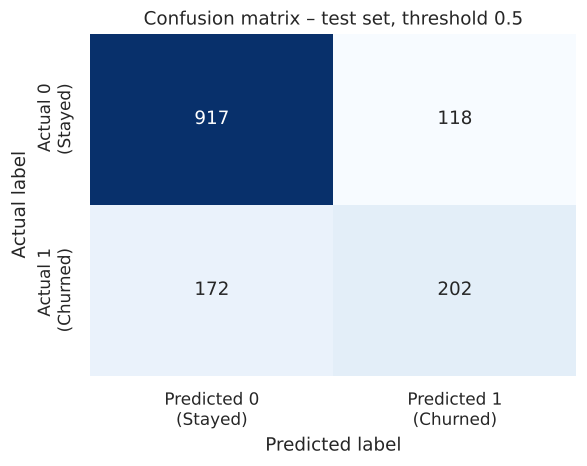

TN =  917  Loyal customers correctly left alone (no offer wasted).
FP =  118  Loyal customers wrongly flagged → a retention offer is spent on someone who would have stayed.
FN =  172  Churners the model MISSED → we never contact them, revenue is lost.
TP =  202  Churners correctly flagged → we get the chance to save them.


In [15]:
cm = confusion_matrix(y_test, pred_05)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted 0\n(Stayed)", "Predicted 1\n(Churned)"], yticklabels=["Actual 0\n(Stayed)", "Actual 1\n(Churned)"])
ax.set_title("Confusion matrix – test set, threshold 0.5")
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label")
savefig("06_confusion_matrix_t05")

print(f"TN = {tn:4d}  Loyal customers correctly left alone (no offer wasted).")
print(f"FP = {fp:4d}  Loyal customers wrongly flagged → a retention offer is spent on someone who would have stayed.")
print(f"FN = {fn:4d}  Churners the model MISSED → we never contact them, revenue is lost.")
print(f"TP = {tp:4d}  Churners correctly flagged → we get the chance to save them.")

**Reading the confusion matrix (threshold 0.5).** Of the 1,409 test customers: **917 TN** (loyal customers correctly left alone), **118 FP** (loyal customers wrongly flagged), **172 FN** (churners missed) and **202 TP** (churners correctly flagged). In other words, of the 374 customers who really churned, the model found only 202 and missed 172 (46%) – at this default threshold, most of the model's mistakes are the *expensive* kind (missed churners).

### 8.2 Metrics with formulas (threshold 0.5)

In [16]:
acc  = (tp + tn) / (tp + tn + fp + fn)
prec = tp / (tp + fp)
rec  = tp / (tp + fn)
spec = tn / (tn + fp)
f1   = 2 * prec * rec / (prec + rec)
auc  = roc_auc_score(y_test, prob_test)

# cross-check the hand formulas against scikit-learn
assert np.isclose(acc, accuracy_score(y_test, pred_05)) and np.isclose(prec, precision_score(y_test, pred_05))
assert np.isclose(rec, recall_score(y_test, pred_05)) and np.isclose(f1, f1_score(y_test, pred_05))

results_table = pd.DataFrame([
    ["Accuracy",           "(TP + TN) / (TP + TN + FP + FN)",       "Share of all predictions that are correct; misleading when classes are imbalanced.", acc],
    ["Precision",          "TP / (TP + FP)",                        "Of the customers flagged as churn, how many really churn.", prec],
    ["Recall (sensitivity)", "TP / (TP + FN)",                      "Of the customers who really churn, how many the model found.", rec],
    ["Specificity",        "TN / (TN + FP)",                        "Of the customers who really stay, how many the model correctly cleared.", spec],
    ["F1-score",           "2 × (Precision × Recall) / (Precision + Recall)", "Single score balancing precision and recall.", f1],
    ["ROC-AUC",            "Area under the ROC curve",              "Ability to rank churners above stayers across all thresholds (0.5 = chance, 1.0 = perfect).", auc],
], columns=["Metric", "Formula", "What it tells the user", "Your test-set result"])
pd.set_option("display.max_colwidth", 120)
display(results_table.style.format({"Your test-set result": "{:.4f}"}).hide(axis="index"))
results_table.to_csv("results/classification_results_t05.csv", index=False)

Metric,Formula,What it tells the user,Your test-set result
Accuracy,(TP + TN) / (TP + TN + FP + FN),Share of all predictions that are correct; misleading when classes are imbalanced.,0.7942
Precision,TP / (TP + FP),"Of the customers flagged as churn, how many really churn.",0.6312
Recall (sensitivity),TP / (TP + FN),"Of the customers who really churn, how many the model found.",0.5401
Specificity,TN / (TN + FP),"Of the customers who really stay, how many the model correctly cleared.",0.8860
F1-score,2 × (Precision × Recall) / (Precision + Recall),Single score balancing precision and recall.,0.5821
ROC-AUC,Area under the ROC curve,"Ability to rank churners above stayers across all thresholds (0.5 = chance, 1.0 = perfect).",0.8381


**Interpretation (test set, threshold 0.5).**
* **Accuracy 0.794** – 79.4% of all customers are classified correctly; this is only 6 points above the "always Stayed" baseline (73.5%), so on its own it flatters the model.
* **Precision 0.631** – when the model flags a customer as a churner it is right about 63% of the time (about 1 in 3 flags is a wasted offer).
* **Recall 0.540** – the model finds about 54% of the customers who really leave.
* **Specificity 0.886** – 88.6% of loyal customers are correctly left alone.
* **F1 0.582** – the balance of precision and recall; lower than accuracy because the minority class is harder.
* **ROC-AUC 0.838** – see Section 8.5.
For a retention team, **recall (0.54) is the weak spot at the default threshold** – we explore the threshold next.

### 8.3 Full classification report

In [17]:
print(classification_report(y_test, pred_05, target_names=["0 – Stayed", "1 – Churned"], digits=3))

              precision    recall  f1-score   support

  0 – Stayed      0.842     0.886     0.863      1035
 1 – Churned      0.631     0.540     0.582       374

    accuracy                          0.794      1409
   macro avg      0.737     0.713     0.723      1409
weighted avg      0.786     0.794     0.789      1409



**Reading the report.** The "Stayed" class scores well (precision 0.842, recall 0.886, F1 0.863, 1,035 customers). The "Churned" class is clearly weaker (precision 0.631, recall 0.540, F1 0.582, 374 customers). The **macro average F1 (0.723)** treats both classes equally and is therefore lower than the **weighted average (0.789)**, which is dominated by the larger class – another sign that accuracy (0.794) hides how much harder the churn class is.

### 8.4 Comparison with the majority-class baseline

In [18]:
cmp_rows = []
for name, pred, a in [("Majority-class baseline", base_pred, 0.5), ("Logistic Regression (t = 0.5)", pred_05, auc)]:
    cmp_rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
                     "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred, zero_division=0), "ROC-AUC": a})
display(pd.DataFrame(cmp_rows).set_index("Model"))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority-class baseline,0.7346,0.0000,0.0000,0.0000,0.5000
Logistic Regression (t = 0.5),0.7942,0.6312,0.5401,0.5821,0.8381


**Interpretation.** Against the baseline, accuracy rises from 0.735 to 0.794, but the real gain is elsewhere: recall rises from **0 to 0.54** and precision from 0 to 0.63 – the baseline never finds a single churner – and ROC-AUC rises from 0.50 (pure chance) to 0.84. The model clearly beats the benchmark on the metrics that matter. **Why accuracy alone can mislead:** with 73.5% "Stayed", a model that does nothing looks 73.5% accurate.

### 8.5 ROC curve and precision–recall curve

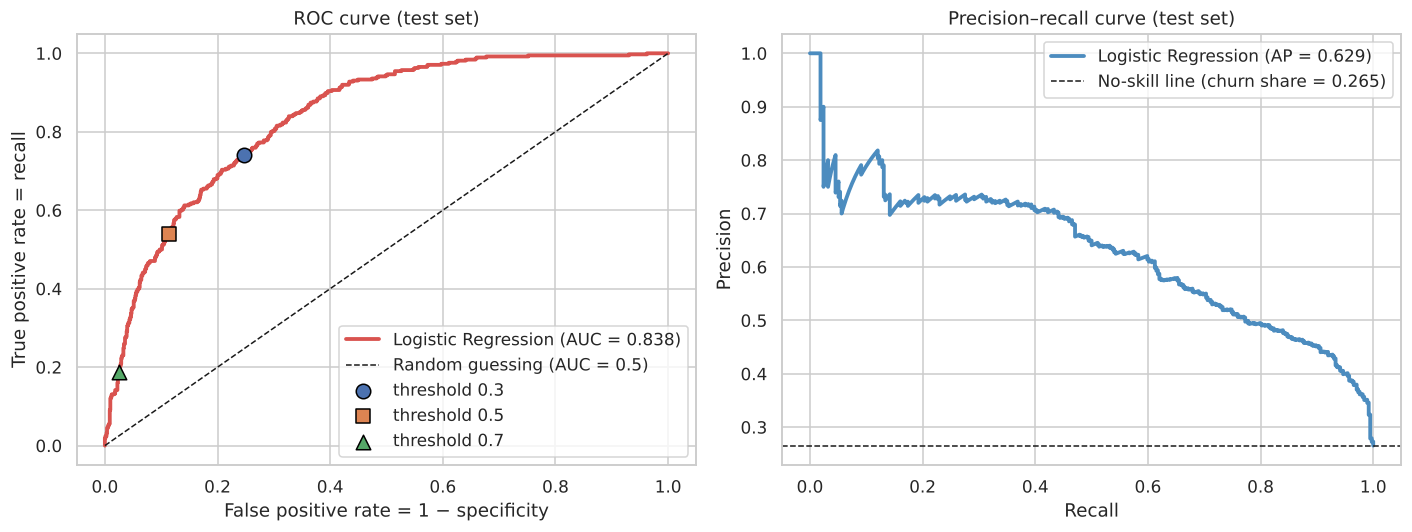

ROC-AUC = 0.8381 | Average precision (area under the PR curve) = 0.6288


In [19]:
fpr, tpr, roc_thr = roc_curve(y_test, prob_test)
prec_c, rec_c, pr_thr = precision_recall_curve(y_test, prob_test)
ap = average_precision_score(y_test, prob_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, lw=2.5, color="#d9534f", label=f"Logistic Regression (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guessing (AUC = 0.5)")
for t, m in [(0.3, "o"), (0.5, "s"), (0.7, "^")]:
    p = (prob_test >= t).astype(int); tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    axes[0].scatter(fp_ / (fp_ + tn_), tp_ / (tp_ + fn_), s=90, marker=m, edgecolor="black", zorder=5, label=f"threshold {t}")
axes[0].set_title("ROC curve (test set)"); axes[0].set_xlabel("False positive rate = 1 − specificity"); axes[0].set_ylabel("True positive rate = recall")
axes[0].legend(loc="lower right")

axes[1].plot(rec_c, prec_c, lw=2.5, color="#4c8cbf", label=f"Logistic Regression (AP = {ap:.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"No-skill line (churn share = {y_test.mean():.3f})")
axes[1].set_title("Precision–recall curve (test set)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
savefig("07_roc_and_pr_curves")
print(f"ROC-AUC = {auc:.4f} | Average precision (area under the PR curve) = {ap:.4f}")

**Interpretation.**
* **ROC-AUC = 0.838.** If we pick one customer who churned and one who stayed at random, the model gives the churner the higher churn probability about 84% of the time (0.5 would be a coin flip, 1.0 perfect). This is *ranking* ability, independent of any threshold. The three marked points show where thresholds 0.3, 0.5 and 0.7 sit on the same curve: lower threshold = more churners caught (higher recall) but more false alarms.
* **Precision–recall curve.** Because the classes are imbalanced, the PR curve is more informative: average precision is **0.629** against a no-skill level of 0.265 (the churn share), about 2.4 times better than chance. Precision falls as recall rises – to catch most churners we must accept many false alarms.

### 8.6 Threshold comparison (0.3, 0.5, 0.7)

In [20]:
def metrics_at(y_true, prob, t):
    pred = (prob >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_true, pred).ravel()
    return {"Threshold": t, "Predicted positive": int(pred.sum()), "TP": tp_, "FP": fp_, "FN": fn_, "TN": tn_,
            "Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred), "F1-score": f1_score(y_true, pred, zero_division=0)}

thr_table = pd.DataFrame([metrics_at(y_test, prob_test, t) for t in (0.3, 0.5, 0.7)])
display(thr_table.style.format({"Threshold": "{:.1f}", "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1-score": "{:.3f}"}).hide(axis="index"))
thr_table.to_csv("results/threshold_comparison.csv", index=False)

Threshold,Predicted positive,TP,FP,FN,TN,Accuracy,Precision,Recall,F1-score
0.3,532,277,255,97,780,0.750,0.521,0.741,0.611
0.5,320,202,118,172,917,0.794,0.631,0.540,0.582
0.7,96,70,26,304,1009,0.766,0.729,0.187,0.298


**The precision–recall trade-off in numbers.**
* **Threshold 0.3:** flags 532 customers; recall rises to **0.741** (277 of 374 churners found) but precision drops to **0.521** (255 false alarms); F1 is the best of the three (0.611).
* **Threshold 0.5:** flags 320; precision 0.631, recall 0.540, accuracy highest (0.794).
* **Threshold 0.7:** flags only 96; precision is highest (**0.729**) but recall collapses to **0.187** – we would miss 304 of 374 churners.
Raising the threshold makes the model more *cautious* (fewer, more certain flags, higher precision, lower recall); lowering it makes the model more *generous* (more churners caught, more false alarms). Accuracy peaks near 0.5 only because it rewards the many easy "Stayed" cases; it is not the right yardstick for this business problem.

### 8.7 Training versus test performance (over-/under-fitting check)

In [21]:
prob_train = model.predict_proba(X_train)[:, 1]
tt = pd.DataFrame({
    "Training set": {"Accuracy": accuracy_score(y_train, prob_train >= .5), "Precision": precision_score(y_train, prob_train >= .5),
                     "Recall": recall_score(y_train, prob_train >= .5), "F1": f1_score(y_train, prob_train >= .5), "ROC-AUC": roc_auc_score(y_train, prob_train)},
    "Test set":     {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1, "ROC-AUC": auc}})
tt["Gap (train − test)"] = tt["Training set"] - tt["Test set"]
display(tt)

,Training set,Test set,Gap (train − test)
Accuracy,0.8055,0.7942,0.0113
Precision,0.6626,0.6312,0.0313
Recall,0.5438,0.5401,0.0037
F1,0.5974,0.5821,0.0152
ROC-AUC,0.8476,0.8381,0.0095


**Over-/under-fitting check.** Training and test results are very close (ROC-AUC 0.848 vs 0.838; recall 0.544 vs 0.540; the largest gap is 0.03 in precision). There is **no meaningful overfitting**. Performance is moderate rather than excellent, which suggests the limit comes from the information in the features and from the simple linear form, not from memorisation – so a more complex model might help a little, but this is a solid, honest baseline.

## 9. Choosing the threshold for the business  *(stage 6 – which error hurts most?)*

**Which error is more costly here?** A **false negative** (a lost customer) costs far more than a **false positive** (a retention offer given to someone who would have stayed). But *how much* more is a business number we do not have. To make the reasoning explicit and repeatable, we use an **illustrative cost ratio**:

* cost of one false positive = **1 unit** (the cost of an unnecessary retention offer),
* cost of one false negative = **r units** (the value lost when a churner is not retained). We use **r = 5** as the working assumption and show r = 2 and r = 10 to see how sensitive the answer is.

> ⚠️ **These ratios are assumptions for demonstration.** A real team must replace them with its own figures (offer cost, customer lifetime value, probability that an offer actually retains someone).

**To avoid cheating, the threshold is chosen using 5-fold cross-validated probabilities on the *training* set**, never on the test set. The test set then reports how the chosen threshold performs on unseen customers.

Cost ratio r (FN = r × FP),Best threshold (from CV on train),Test: flagged,Test precision,Test recall,Test F1
2,0.34,488,0.541,0.706,0.613
5,0.16,762,0.445,0.906,0.597
10,0.12,843,0.415,0.936,0.575


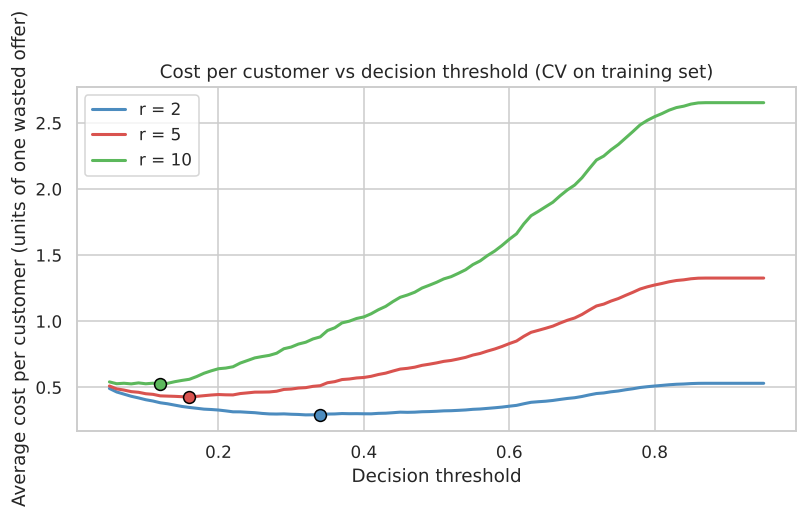


Recommended working threshold (r = 5): 0.16


In [22]:
# out-of-fold predicted probabilities on the TRAINING data (preprocessing is re-fitted inside every fold)
oof_prob = cross_val_predict(make_pipeline(NUM, CAT), X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)

def total_cost(y_true, prob, t, r):
    pred = prob >= t
    fp_ = int(((pred) & (y_true == 0)).sum()); fn_ = int(((~pred) & (y_true == 1)).sum())
    return fp_ * 1 + fn_ * r

best = {}
rows = []
for r in (2, 5, 10):
    costs = np.array([total_cost(y_train.values, oof_prob, t, r) for t in grid])
    best[r] = float(grid[costs.argmin()])
    m = metrics_at(y_test, prob_test, best[r])
    rows.append({"Cost ratio r (FN = r × FP)": r, "Best threshold (from CV on train)": best[r], "Test: flagged": m["Predicted positive"],
                 "Test precision": m["Precision"], "Test recall": m["Recall"], "Test F1": m["F1-score"]})
display(pd.DataFrame(rows).style.format({"Best threshold (from CV on train)": "{:.2f}", "Test precision": "{:.3f}", "Test recall": "{:.3f}", "Test F1": "{:.3f}"}).hide(axis="index"))

R = 5
THRESHOLD = best[R]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for r, col in zip((2, 5, 10), ("#4c8cbf", "#d9534f", "#5cb85c")):
    c = np.array([total_cost(y_train.values, oof_prob, t, r) for t in grid]) / len(y_train)
    ax.plot(grid, c, color=col, lw=2, label=f"r = {r}")
    ax.scatter([best[r]], [min(c)], color=col, s=60, zorder=5, edgecolor="black")
ax.set_title("Cost per customer vs decision threshold (CV on training set)")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Average cost per customer (units of one wasted offer)"); ax.legend()
savefig("08_cost_vs_threshold")
print(f"\nRecommended working threshold (r = {R}): {THRESHOLD:.2f}")

**Threshold recommendation.** The more costly error is the **false negative** (a lost customer). Choosing the threshold that minimises expected cost on cross-validated training predictions gives **0.34 for r = 2, 0.16 for r = 5 and 0.12 for r = 10** – i.e. the more a missed churner costs, the lower the threshold. For the working assumption **r = 5** we recommend **t ≈ 0.16**: on the test set this flags about 54% of customers and finds about 91% of the churners (recall ≈ 0.91), but only about 44% of flags are real churners (precision ≈ 0.44). **The trade-off we accept:** many false alarms in exchange for catching almost every churner. If the real cost ratio is smaller (about 2), the better threshold is nearer 0.34; if the team can contact only a limited number of customers, the capacity view below is more practical than a fixed threshold.

In [23]:
# Final test-set evaluation at the recommended threshold, and cost comparison with simple strategies
final = metrics_at(y_test, prob_test, THRESHOLD)
display(pd.DataFrame([metrics_at(y_test, prob_test, t) for t in (0.5, THRESHOLD)]).style.format(
    {"Threshold": "{:.2f}", "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1-score": "{:.3f}"}).hide(axis="index"))

n_pos, n_neg = int(y_test.sum()), int((y_test == 0).sum())
strategies = {
    "Contact nobody (predict all 'Stayed')":     n_pos * R,
    "Contact everybody":                         n_neg * 1,
    "Model, threshold 0.7":                      total_cost(y_test.values, prob_test, 0.7, R),
    "Model, threshold 0.5":                      total_cost(y_test.values, prob_test, 0.5, R),
    "Model, threshold 0.3":                      total_cost(y_test.values, prob_test, 0.3, R),
    f"Model, recommended threshold {THRESHOLD:.2f}": total_cost(y_test.values, prob_test, THRESHOLD, R),
}
cost_df = pd.DataFrame({"Total cost on test set (r = 5)": strategies})
cost_df["Cost per customer"] = cost_df.iloc[:, 0] / len(y_test)
display(cost_df.sort_values("Total cost on test set (r = 5)"))
cost_df.to_csv("results/cost_comparison.csv")

Threshold,Predicted positive,TP,FP,FN,TN,Accuracy,Precision,Recall,F1-score
0.50,320,202,118,172,917,0.794,0.631,0.540,0.582
0.16,762,339,423,35,612,0.675,0.445,0.906,0.597


,Total cost on test set (r = 5),Cost per customer
"Model, recommended threshold 0.16",598,0.4244
"Model, threshold 0.3",740,0.5252
"Model, threshold 0.5",978,0.6941
Contact everybody,1035,0.7346
"Model, threshold 0.7",1546,1.0972
Contact nobody (predict all 'Stayed'),1870,1.3272


**Interpretation.** Under the r = 5 assumption, the model at the recommended threshold costs 598 units on the test set, against 1,035 for contacting everybody and 1,870 for contacting nobody – about **42% cheaper than contacting everyone** and about **39% cheaper than using the default 0.5 threshold** (978). A very high threshold (0.7) is *worse than contacting everybody* (1,546 vs 1,035), because it misses so many churners. The key point: **the same model can be a good or a bad business tool depending on the threshold**; the default 0.5 was not the best choice here. Remember that these figures hinge on the assumed ratio r.

In [24]:
# Capacity view: what if the team can only contact the highest-risk X% of customers?
order = np.argsort(-prob_test)
churn_sorted = y_test.values[order]
rows = []
for share in (0.10, 0.20, 0.30, 0.40, 0.50):
    k = int(round(share * len(order)))
    caught = churn_sorted[:k].sum()
    rows.append({"Contact top X% highest-risk": f"{share:.0%}", "Customers contacted": k, "Churners reached": int(caught),
                 "Share of all churners reached": caught / n_pos, "Lift vs random": (caught / k) / y_test.mean()})
display(pd.DataFrame(rows).style.format({"Share of all churners reached": "{:.1%}", "Lift vs random": "{:.2f}"}).hide(axis="index"))

Contact top X% highest-risk,Customers contacted,Churners reached,Share of all churners reached,Lift vs random
10%,141,103,27.5%,2.75
20%,282,185,49.5%,2.47
30%,423,244,65.2%,2.17
40%,564,286,76.5%,1.91
50%,704,326,87.2%,1.74


**Interpretation.** If the team can only contact the 10% of customers the model considers riskiest (141 customers), it reaches **27.5%** of all churners – 2.75 times better than picking at random. Contacting the top 20% reaches about half of all churners (49.5%) and the top 30% reaches about two thirds (65.2%). This ranking view needs no threshold and fits real-world capacity limits.

## 10. Visualise the decision behaviour  *(stage 9 of the activity)*
We vary one feature – `tenure` – for a fixed reference customer and plot the predicted churn probability for each contract type.

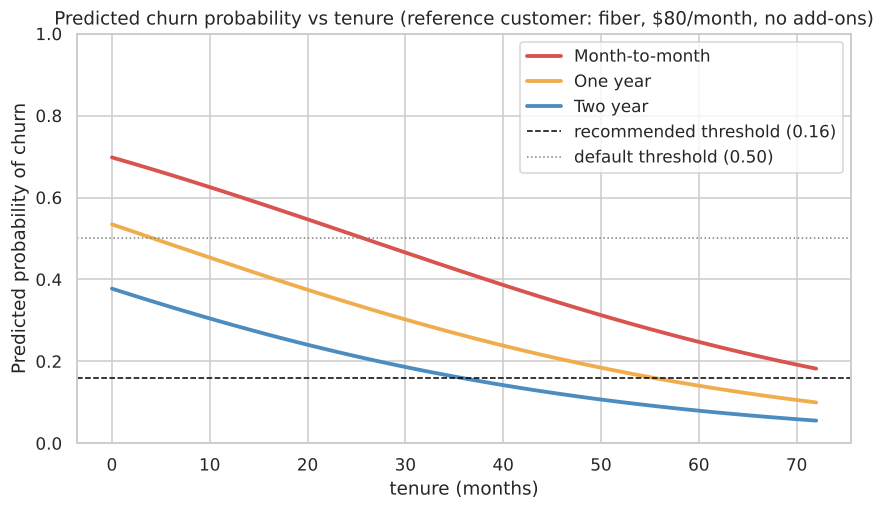

In [25]:
reference = {"Partner": "No", "Dependents": "No", "PhoneService": "Yes", "InternetService": "Fiber optic", "PaperlessBilling": "Yes",
             "PaymentMethod": "Electronic check", "MonthlyCharges": 80.0,
             **{c: "No" for c in addon_cols}}
tenure_grid = np.arange(0, 73)
fig, ax = plt.subplots(figsize=(8, 4.8))
for contract, col in zip(["Month-to-month", "One year", "Two year"], ["#d9534f", "#f0ad4e", "#4c8cbf"]):
    g = pd.DataFrame([{**reference, "tenure": t, "Contract": contract} for t in tenure_grid])[FEATURES]
    ax.plot(tenure_grid, model.predict_proba(g)[:, 1], lw=2.5, color=col, label=contract)
ax.axhline(THRESHOLD, color="black", ls="--", lw=1, label=f"recommended threshold ({THRESHOLD:.2f})")
ax.axhline(0.5, color="grey", ls=":", lw=1, label="default threshold (0.50)")
ax.set_ylim(0, 1)
ax.set_title("Predicted churn probability vs tenure (reference customer: fiber, $80/month, no add-ons)")
ax.set_xlabel("tenure (months)"); ax.set_ylabel("Predicted probability of churn"); ax.legend()
savefig("09_probability_vs_tenure")

**What the plot shows.** For every contract type, the predicted churn probability **falls steadily as tenure grows** – new customers are the riskiest. At the same tenure, month-to-month customers always have the highest probability and two-year customers the lowest (at tenure 0: about 0.70, 0.53 and 0.38). Even after 72 months the month-to-month curve (about 0.18) is still above the recommended threshold of 0.16, while the two-year curve falls below it after about 36 months – so with the low recommended threshold a long-standing month-to-month fiber customer would still be flagged, which is the price of a cautious threshold. At the default 0.5, hardly any long-tenure customer is ever flagged. The three curves are parallel on the log-odds scale: this is an assumption of the model (no interaction between contract and tenure).

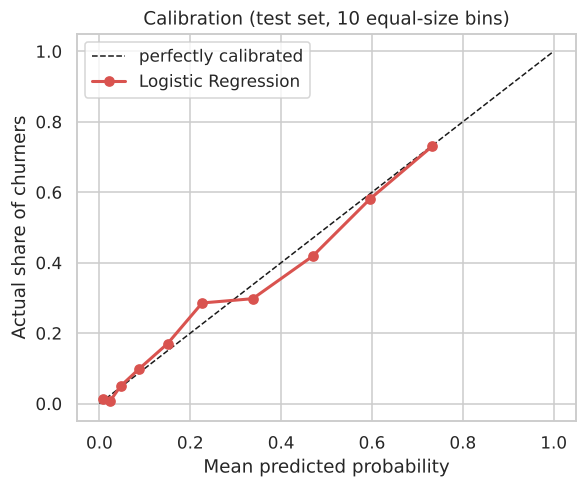

In [26]:
# Are the predicted probabilities trustworthy as probabilities?  (calibration check on the test set)
frac_pos, mean_pred = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
ax.plot(mean_pred, frac_pos, "o-", color="#d9534f", lw=2, label="Logistic Regression")
ax.set_title("Calibration (test set, 10 equal-size bins)")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Actual share of churners"); ax.legend()
savefig("10_calibration")

**Interpretation.** The points lie close to the diagonal, so when the model says "30%" roughly 30% of such customers really churn – the probabilities can be read as probabilities, not just scores. Small deviations (slightly too confident in the 0.3–0.5 range) are within what is expected with about 140 customers per bin.

## 11. Classify new examples and conclude  *(stage 8)*

In [27]:
new_customers = pd.DataFrame([
    {"label": "A – new customer, month-to-month, fiber, no support", "tenure": 4, "MonthlyCharges": 85.0, "Contract": "Month-to-month",
     "InternetService": "Fiber optic", "PaymentMethod": "Electronic check", "PaperlessBilling": "Yes", "Partner": "No", "Dependents": "No",
     "PhoneService": "Yes", "MultipleLines": "No", "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No",
     "TechSupport": "No", "StreamingTV": "Yes", "StreamingMovies": "Yes"},
    {"label": "B – long-term, two-year contract, DSL, with support", "tenure": 48, "MonthlyCharges": 55.0, "Contract": "Two year",
     "InternetService": "DSL", "PaymentMethod": "Bank transfer (automatic)", "PaperlessBilling": "No", "Partner": "Yes", "Dependents": "Yes",
     "PhoneService": "Yes", "MultipleLines": "No", "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "No",
     "TechSupport": "Yes", "StreamingTV": "No", "StreamingMovies": "No"},
])
# same preprocessing automatically: the pipeline applies the training-fitted scaler and encoder
p_new = model.predict_proba(new_customers[FEATURES])[:, 1]
out = new_customers[["label", "tenure", "MonthlyCharges", "Contract"]].copy()
out["P(churn)"] = p_new
out[f"label at default t=0.50"] = np.where(p_new >= 0.5, "1 – Churn", "0 – Stay")
out[f"label at recommended t={THRESHOLD:.2f}"] = np.where(p_new >= THRESHOLD, "1 – Churn → contact", "0 – Stay → no action")
display(out)

# range check for the numeric inputs (no extrapolation)
for c in NUM:
    assert X_train[c].min() <= new_customers[c].min() and new_customers[c].max() <= X_train[c].max(), f"{c} outside training range"
print("All numeric inputs lie inside the training range.")

,label,tenure,MonthlyCharges,Contract,P(churn),label at default t=0.50,label at recommended t=0.16
0,"A – new customer, month-to-month, fiber, no support",4,85.0000,Month-to-month,0.7972,1 – Churn,1 – Churn → contact
1,"B – long-term, two-year contract, DSL, with support",48,55.0000,Two year,0.0085,0 – Stay,0 – Stay → no action


All numeric inputs lie inside the training range.


**Reading the predictions.** Customer **A** (4 months with the company, month-to-month contract, fiber, no support, streaming add-ons) gets a churn probability of **0.80** and is flagged at both the default and the recommended threshold → the team should contact them. Customer **B** (48 months, two-year contract, DSL, with security and support) gets **0.009**, i.e. practically no risk → no action. These probabilities are estimates, not guarantees – a customer with 0.80 may still stay.

In [28]:
joblib.dump({"pipeline": model, "features": FEATURES, "recommended_threshold": THRESHOLD, "cost_ratio_assumed": R},
            "models/churn_logreg_pipeline.joblib")
print("Saved: models/churn_logreg_pipeline.joblib  (pipeline = scaler + one-hot encoder + logistic regression)")

Saved: models/churn_logreg_pipeline.joblib  (pipeline = scaler + one-hot encoder + logistic regression)


### 11.1 Conclusion (for a non-technical manager)
* **What we did:** used 7,043 telecom customers (IBM sample data) to estimate each customer's chance of leaving, using their contract, services, billing choices, tenure and monthly charge – without gender or age-related information.
* **What we found:** the model ranks customers well (ROC-AUC 0.84; it puts a real churner above a real stayer about 84% of the time) and beats the "nobody churns" baseline by a large margin on the metrics that matter. At the default 0.5 cut-off it finds only 54% of churners (precision 63%).
* **Biggest risk signals:** short tenure, month-to-month contracts, fiber-optic internet and electronic-check payment; lower risk comes with long contracts, long tenure, online security and tech support. These are patterns, not proven causes.
* **Key decision – the threshold:** the default 0.5 is not the best choice when a lost customer costs more than a wasted offer. With an illustrative 5:1 cost ratio, a threshold of about **0.16** cut the total cost by about 42% compared with contacting everyone and by about 39% compared with using 0.5, at the price of many false alarms. If the retention budget is limited, contacting the top 20% riskiest customers reaches about half of all churners.
* **Limits:** the cost ratio is an assumption; the data is one sample snapshot; the model is a ranking aid for human decisions and must not be used to deny service or set prices for an individual.

## 12. Decision log, limitations and ethics

### 12.1 Decision log
| # | Decision | Alternatives considered | Reason |
|---|---|---|---|
| 1 | Dataset: Telco Customer Churn (7,043 customers, IBM sample data) | Small 2-feature toy datasets | Realistic business problem with a clear cost trade-off, mixed numeric/categorical features and moderate class imbalance; easy to extend |
| 2 | Positive class = "Churned" | Positive = "Stayed" | The team acts on churners, so "positive" must be the event we want to catch |
| 3 | Fill 11 blank `TotalCharges` with 0 | Drop the rows | All have tenure 0 (not yet billed); they are valid customers |
| 4 | Merge "No internet service"/"No phone service" into "No" | Keep three labels | The extra label repeats `InternetService`/`PhoneService`; fewer redundant columns |
| 5 | Drop `customerID`, `gender`, `SeniorCitizen`, `TotalCharges` | Keep all | ID = no behaviour; gender/age flag = fairness risk in who gets offers; TotalCharges ≈ tenure × monthly (redundant); cross-validated AUC barely changes (Section 4) |
| 6 | One-hot encoding (first category dropped) + standardise numeric features | Label encoding; no scaling | No natural order in categories; scaling helps the optimiser and makes coefficients comparable; all fitted inside a Pipeline on training data only |
| 7 | Stratified 80:20 split, seed 42 | Random split | Keeps the 26.5% churn share in both parts |
| 8 | Main metric: recall (with precision and F1 alongside), PR-AUC and an explicit cost calculation | Accuracy | A missed churner costs more than a wasted offer; accuracy is misleading at 73.5% majority |
| 9 | Threshold chosen on cross-validated training predictions, illustrative cost ratio r = 5 | Default 0.5; choose on test set | 0.5 ignores unequal costs; choosing on test data would leak; r is an assumption to be replaced by real figures |
| 10 | Plain Logistic Regression (L2, C = 1, no class weights) | Class-weighted model, SMOTE, tree models | Activity scope; keeps probabilities calibrated and coefficients explainable; reweighting would be a later experiment |

### 12.2 Limitations – what this model must **not** be used for
* **Not as the sole decision-maker.** It should *rank* customers for a human-run retention programme. It must not be used to deny service, change prices or penalise an individual customer.
* **A probability is an estimate, not a guarantee.** A customer with P = 0.8 may well stay, and one with P = 0.1 may leave.
* **It predicts association, not cause.** For example, customers on month-to-month contracts churn more, but moving a customer to a two-year contract does not necessarily make them stay – loyal customers may simply choose longer contracts.
* **Sample data from one snapshot.** One period, one (fictional) company; behaviour, competition and prices change. It needs re-training and monitoring before any real use.
* **The cost ratio is a placeholder.** The recommended threshold depends entirely on real offer costs and customer value.
* **Several coefficients are conditional.** For instance the `MonthlyCharges` coefficient is small and negative *after* contract, internet type and add-ons are accounted for, because the price is largely determined by those services. It must not be read as "higher prices reduce churn".

### 12.3 Ethics and who could be affected
* **Wrongly flagged customers (FP)** may receive offers others do not – a fairness issue if repeated, and a cost to the company. **Missed customers (FN)** receive no attention and may leave.
* We deliberately **excluded gender and the senior-citizen flag**. Other included features can still act as indirect proxies for protected characteristics (for example, payment method or contract type correlating with income or age). Before real use, error rates should be audited across groups.
* The data contains no names or contact details, and all work in this notebook uses anonymous account-level data.

### 12.4 If this project is expanded later
1. Compare with class-weighted Logistic Regression, KNN, SVM (Activity 3), random forest and gradient boosting.
2. Tune the regularisation strength `C` with cross-validation and try interaction terms (e.g. contract × tenure).
3. Replace the illustrative cost ratio with real offer costs and customer lifetime value, and optimise expected profit.
4. Add explainability (SHAP / permutation importance) and per-customer "reason codes".
5. Audit fairness across customer groups and calibrate probabilities (Platt / isotonic).
6. Wrap the saved pipeline in a Streamlit or FastAPI app that scores a customer record and returns the risk and recommended action.